# Lab work # 2: Dive deeper into principles of classification methods

> Student name    - Rodion

> Student surname - Ostapenko

> Group           - KS-32


# Task description

## Part 1 (playing with generated data)

1. Set your `STUDENT_ID`, which is used as random seed, and makes your data looks a bit different.
2. Looks through `1.3. Example of using tool & experiments`, use all provided data in your experiments. But you can generate your own (more interesting & complex artificial data from your perspective)
3. In the `1.4. Task & your experiments` part do your experiments, as described select all (or a few) datasets and conduct experiments with each of the proposed methods. The idea here is to understand how various configurations of hyperparameters influence on space separations. Consider using provided hints.
4. Don't forget to write your conclusions & observations.

## Part 2 (working on the real classification problem)

1. Select 1-3 the most fascinating classification method depending on your taste.
2. Select 1 of the provided (look at the section bellow) real data for experiment.
3. Conduct experiments as shown in the example on [GitHub Repo](https://github.com/VolDonets/ML_basics_course/tree/master/lab_works/lab_3)
4. But consider tuning hyperparameters of your selected models as it was in this work and observe performance.
5. **BONUS** (+2 points): take modify function `def plot_classifier_boundary_by_dots(X, y, model=None, title=None, n_background_points=10_000): ...` to visualize decision boundaries on your real data from experiments. Hint: Here you need fit `PCA(n_components=2)`, `t-SNE`, `UMAP`  on the `X` data and used it on `X` and on `X_background` before visualizing. Also, consider that `X` and `X_background` should have the same dimension. Be aware that such visualizing might looks weird cause PCA might weirdly transform evenly distributed data in `X_background`, and it's OK.

### Part 2

In [4]:
STUDENT_ID = 20

In [140]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
from sklearn.preprocessing import MinMaxScaler, StandardScaler

import time

In [135]:
def train_classification_models(X_train, X_test, y_train, y_test, sort_by="Accuracy", lr=True, rf=True, gnb=True, svc=True):
    models = {}
    if lr:
        models["Logistic Regression"] = LogisticRegression(max_iter=1000, random_state=STUDENT_ID)
    if rf:
        models["Random Forest"] = RandomForestClassifier(n_estimators=500, random_state=STUDENT_ID, n_jobs=-1, criterion="entropy")
    if gnb:
        models["GaussianNB"] = GaussianNB()
    if svc:
        models["SVC"] = SVC()

    metrics_report = []
    
    for model_name, model in models.items():
        start_time = time.time()
        
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_test)
        
        if model_name == "SVC":
            train_time = time.time() - start_time
        
            metrics_report.append({
                "Model": model_name,
                "Accuracy": accuracy_score(y_test, y_pred),
                "Precision (CT)": precision_score(y_test, y_pred),
                "Recall (CT)": recall_score(y_test, y_pred),
                "F1 Score": f1_score(y_test, y_pred),
                "ROC AUC": "-",
                "Time (sec)": round(train_time, 2)
            })
        else:
            y_prob = model.predict_proba(X_test)[:, 1]
            
            train_time = time.time() - start_time
            
            metrics_report.append({
                "Model": model_name,
                "Accuracy": accuracy_score(y_test, y_pred),
                "Precision (CT)": precision_score(y_test, y_pred),
                "Recall (CT)": recall_score(y_test, y_pred),
                "F1 Score": f1_score(y_test, y_pred),
                "ROC AUC": roc_auc_score(y_test, y_prob),
                "Time (sec)": round(train_time, 2)
            })
        
    report_df = pd.DataFrame(metrics_report)
    report_df = report_df.sort_values(by=sort_by, ascending=False).reset_index(drop=True)
    print(report_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    return models

In [136]:
def visualize_feature_importance(model, X, positive_threshold=0.1, negative_threshold=-0.1, model_type="Logistic Regression"):
    if model_type == "Logistic Regression":
        importances = pd.DataFrame({
            'Feature': X,
            'Importance': model.coef_[0]
        })
        
    elif model_type == "Random Forest":
        importances = pd.DataFrame({
            'Feature': X,
            'Importance': model.feature_importances_
        })
        
    importances = importances.sort_values(by='Importance', ascending=False)
    importances_pos = importances[(importances['Importance'] > positive_threshold) & (importances['Importance'] > 0)]
    if model_type == "Logistic Regression":
        importances_neg = importances[(importances['Importance'] < negative_threshold) & (importances['Importance'] < 0)]
        importances = pd.concat([importances_pos, importances_neg], axis=0)
    else:
        importances = importances_pos
    
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.barplot(data=importances, x='Importance', y='Feature', ax=ax, palette='mako', hue="Feature")
    
    ax.set_title(f"Feature importance {model_type}")
    ax.set_xlabel("Weight")
    ax.set_ylabel("Feature")
    ax.grid(axis='x', linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()
    
    print(importances.to_string(index=False))

In [141]:
splits = {'train': 'train.csv', 'validation': 'valid.csv', 'test': 'test.csv'}
df = pd.read_csv("hf://datasets/AI4Protein/eSOL/" + splits["train"])
test_df = pd.read_csv("hf://datasets/AI4Protein/eSOL/" + splits["test"])

In [122]:
df["label"].median()

np.float64(0.44)

In [123]:
df.loc[df["label"] >= 0.44, "label"] = 1
df.loc[df["label"] < 0.44, "label"] = 0
test_df.loc[test_df["label"] >= 0.44, "label"] = 1
test_df.loc[test_df["label"] < 0.44, "label"] = 0

In [124]:
df.head(10)

,name,aa_seq,gene,label
0,P0ABL8,MMFWRIFRLELRVAFRHSAEIANPLWFFLIVITLFPLSIGPEPQLLARIAPGIIWVAALLSSLLALERLFRDDLQDGSLEQLMLLPLPLPAVVLAKVMAHWMVTGLPLLILSPLVAMLLGMDVYGWQVMALTLLLGTPTLGFLGAPGVALTVGLKRGGVLLSILVLPLTIPLLIFATAAMDAASMHLPVDGYLAILGALLAGTATLSPFATAAALRISIQ,ccmB,0.0
1,P77721,MAAKDRIQAIKQMVANDKKVTVSNLSGIFQVTEETIRRDLEKLEDEGFLTRTYGGAVLNTAMLTENIHFYKRASSFYEEKQLIARKALPFIDNKTTMAADSSSTVMELLKLLQDRSGLTLLTNSAEAIHVLAQSEIKVVSTGGELNKNTLSLQGRITKEIIRRYHVDIMVMSCKGLDINSGALDSNEAEAEIKKTMIRQATEVALLVDHSKFDRKAFVQLADFSHINYIITDKSPGAEWIAFCKDNNIQLVW,ydjF,0.0
2,Q47152,MSEYRRYYIKGGTWFFTVNLRNRRSQLLTTQYQMLRHAIIKVKRDRPFEINAWVVLPEHMHCIWTLPEGDDDFSSRWREIKKQFTHACGLKNIWQPRFWEHAIRNTKDYRHHVDYIYINPVKHGWVKQVSDWPFSTFHRDVARGLYPIDWAGDVTDFSAGERIIS,yafM,1.0
3,P30958,MPEQYRYTLPVKAGEQRLLGELTGAACATLVAEIAERHAGPVVLIAPDMQNALRLHDEISQFTDQMVMNLADWETLPYDSFSPHQDIISSRLSTLYQLPTMQRGVLIVPVNTLMQRVCPHSFLHGHALVMKKGQRLSRDALRTQLDSAGYRHVDQVMEHGEYATRGALLDLFPMGSELPYRLDFFDDEIDSLRVFDVDSQRTLEEVEAINLLPAHEFPTDKAAIELFRSQWRDTFEVKRDPEHIYQQVSKGTLPAGIEYWQPLFFSEPLPPLFSYFPANTLLVNTGDLETSAERFQADTLARFENRGVDPMRPLLPPQSLWLRVDELFSELKNWPRVQLKTEHLPTKAANANLGFQKLPDLAVQAQQKAPLDALRKFLETFDGPVVFSVESEGRREALGELLARIKIAPQRIMRLDEASDRGRYLMIGAAEHGFVDTVRNLALICESDLLGERVARRRQDSRRTINPDTLIRNLAELHIGQPVVHLEHGVGRYAGMTTLEAGGITGEYLMLTYANDAKLYVPVSSLHLISRYAGGAEENAPLHKLGGDAWSRARQKAAEKVRDVAAELLDIYAQRAAKEGFAFKHDREQYQLFCDSFPFETTPDQAQAINAVLSDMCQPLAMDRLVCGDVGFGKTEVAMRAAFLAVDNHKQVAVLVPTTLLAQQHYDNFRDRFANWPVRIEMISRFRSAKEQTQILAEVAEGKIDILIGTHKLLQSDVKFKDLGLLIVDEEHRFGVRHKERIKAMRANVDILTLTATPIPRTLNMAMSGMRDLSIIATPPARRLAVKTFVREYDSMVVREAILREILRGGQVYYLYNDVENIQKAAERLAELVPEARIAIGHGQMRERELERVMNDFHHQRFNVLVCTTIIETGIDIPTANTIIIERADHFGLAQLHQLRGRVGRSHHQAYAWLLTPHPKAMTTDAQKRLEAIASLEDLGAGFALATHDLEIRGAGELLGEEQSGSMETIGFSLYMELLENAVDALKAGREPSLEDLTSQQTEVELRMPSLLPDDFIPDVNTRLSFYKRIASAKTENELEEIKVELIDRFGLLPDPARTLLDIARLRQQAQKLGIRKLEGNEKGGVIEFAEKNHVNPAWLIGLLQKQPQHYRLDGPTRLKFIQDLSERKTRIEWVRQFMRELEENAIA,mfd,1.0
4,P0C8J8,MKTLIARHKAGEHIGICSVCSAHPLVIEAALAFDRNSTRKVLIEATSNQVNQFGGYTGMTPADFREFVFTIADKVGFARERIILGGDHLGPNCWQQENADAAMEKSVELVKEYVRAGFSKIHLDASMSCAGDPIPLAPETVAERAAVLCFAAESVATDCQREQLSYVIGTEVPVPGGEASAIQSVHITHVEDAANTLRTHQKAFIARGLTEALTRVIAIVVQPGVEFDHSNIIHYQPQEAQPLAQWIENTRMVYEAHSTDYQTRTAYWELVRDHFAILKVGPALTFALREAIFALAQIEQELIAPENRSGCLAVIEEVMLDEPQYWKKYYRTGFNDSLLDIRYSLSDRIRYYWPHSRIKNSVETMMVNLEGVDIPLGMISQYLPKQFERIQSGELSAIPHQLIMDKIYDVLRAYRYGCAE,gatZ,0.0
5,P39829,MANIEIRQETPTAFYIKVHDTDNVAIIVNDNGLKAGTRFPDGLELIEHIPQGHKVALLDIPANGEIIRYGEVIGYAVRAIPRGSWIDESMVVLPEAPPLHTLPLATKVPEPLPPLEGYTFEGYRNADGSVGTKNLLGITTSVHCVAGVVDYVVKIIERDLLPKYPNVDGVVGLNHLYGCGVAINAPAAVVPIRTIHNISLNPNFGGEVMVIGLGCEKLQPERLLTGTDDVQAIPVESASIVSLQDEKHVGFQSMVEDILQIAERHLQKLNQRQRETCPASELVVGMQCGGSDAFSGVTANPAVGYASDLLVRCGATVMFSEVTEVRDAIHLLTPRAVNEEVGKRLLEEMEWYDNYLNMGKTDRSANPSPGNKKGGLANVVEKALGSIAKSGKSAIVEVLSPGQRPTKRGLIYAATPASDFVCGTQQVASGITVQVFTTGRGTPYGLMAVPVIKMATRTELANRWFDLMDINAGTIATGEETIEEVGWKLFHFILDVASGKKKTFSDQWGLHNQLAVFNPAPVT,garD,1.0
6,P52045,MSYQYVNVVTINKVAVIEFNYGRKLNALSKVFIDDLMQALSDLNRPEIRCIILRAPSGSKVFSAGHDIHELPSGGRDPLSYDDPLRQITRMIQKFPKPIISMVEGSVWGGAFEMIMSSDLIIAASTSTFSMTPVNLGVPYNLVGIHNLTRDAGFHIVKELIFTASPITAQRALAVGILNHVVEVEELEDFTLQMAHHISEKAPLAIAVIKEELRVLGEAHTMNSDEFERIQGMRRAVYDSEDYQEGMNAFLEKRKPNFVGH,ygfG,1.0
7,P25889,MLTKDLSITFCGVKFPNPFCLSSSPVGNCYEMCAKAYDTGWGGVVFKTIGFFIANEVSPRFDHLVKEDTGFIGFKNMEQIAEHPLEENLAALRRLKEDYPDKVLIASIMGENEQQWEELARLVQEAGADMIECNFSCPQMTSHAMGSDVGQSPELVEKYCRAVKRGSTLPMLAKMTPNIGDMCEVALAAKRGGADGIAAINTVKSITNIDLNQKIGMPIVNGKSSISGYSGKAVKPIALRFIQQMRTHPELRDFPISGIGGIETWEDAAEFLLLGAATLQVTTGIMQYGYRIVEDMASGLSHYLADQGFDSLQEMVGLANNNIVPAEDLDRSYIVYPRINLDKCVGCGRCYISCYDGGHQAMEWSEKTRTPHCNTEKCVGCLLCGHVCPVGCIELGEVKFKKGEKEHPVTL,yeiA,1.0
8,P0A786,MANPLYQKHIISINDLSRDDLNLVLATAAKLKANPQPELLKHKVIASCFFEASTRTRLSFETSMHRLGASVVGFSDSANTSLGKKGETLADTISVISTYVDAIVMRHPQEGAARLATEFSGNVPVLNAGDGSNQHPTQTLLDLFTIQETQGRLDNLHVAMVGDLKYGRTVHSLTQALAKFDGNRFYFIAPDALAMPQYILDMLDEKGIAWSLHSSIEEVMAEVDILYMTRVQKERLDPSEYANVKAQFVLRASDLHNAKANMKVLHPLPRVDEIATDVDKTPHAWYFQQAGNGIFARQALLALVLNRDLVL,pyrB,1.0
9,P33360,MIEFSHVSKLFGAQKAVNDLNLNFQEGSFSVLIGTSGSGKSTTLKMINRLVEHDSGEIRFAGEEIRSLPVLELRRRMGYAIQSIGL

In [125]:
df["label"].value_counts(normalize=True)

label
1.0    0.500605
0.0    0.499395
Name: proportion, dtype: float64

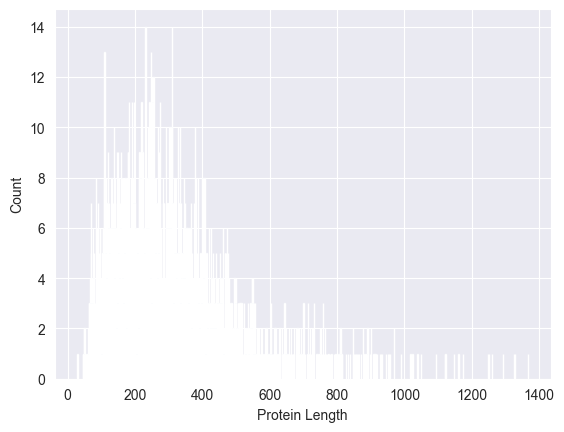

In [76]:
length_distribution = df["aa_seq"].str.len().value_counts()

fig, ax = plt.subplots()
ax.bar(
    length_distribution.index, 
    length_distribution.values)

plt.xlabel("Protein Length")
plt.ylabel("Count")
plt.show()

In [77]:
df["aa_seq"].str.len().median()

np.float64(274.0)

### A)One-Hot-Encoder

In [78]:
def one_hot_encode(sequences: pd.Series, length=200, flatten_output=False):
    alphabet = {char: idx for idx, char in enumerate('ACDEFGHIKLMNPQRSTVWY')}
    
    seqs = sequences.astype(str).str.slice(0, length).tolist()

    tensor = np.zeros((len(seqs), length, 20), dtype=np.int8)
    
    for i, seq in enumerate(seqs):
        for j, char in enumerate(seq):
            if char in alphabet:
                tensor[i, j, alphabet[char]] = 1
                
    if flatten_output:
        return tensor.reshape(len(seqs), -1)
    
    return tensor

print(f"3D shape: {one_hot_encode(df["aa_seq"]).shape}")
print(f"Flattened shape: {one_hot_encode(df["aa_seq"], flatten_output=True).shape}")

3D shape: (2481, 200, 20)
Flattened shape: (2481, 4000)


### B)K-mer Counter

In [79]:
import itertools
def kmer_counter(sequences: pd.Series, k=3):
    alphabet = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']
    kmers = itertools.product(alphabet, repeat=k)
    kmers = {"".join(kmer): idx for idx, kmer in enumerate(kmers)}
    tensor = np.zeros((len(sequences), len(kmers)), dtype=np.int32)
    for i, seq in enumerate(sequences):
        for j, char in enumerate(seq):
            if j+k > len(seq):
                break
            kmer = seq[j:j + k]
            tensor[i, kmers[kmer]] += 1            
    return tensor, kmers.keys()
print(f"k=2 shape: {kmer_counter(df["aa_seq"], k=2)[0].shape}")
print(f"k=3 shape: {kmer_counter(df["aa_seq"])[0].shape}")

k=2 shape: (2481, 400)
k=3 shape: (2481, 8000)


### C)Physicochemical Extractor

In [109]:
from Bio.SeqUtils.ProtParam import ProteinAnalysis

def extract_physicochemical_features(sequences: pd.Series, 
            aa_counts=False, aa_percents=True, molecular_weight=True, aromaticity=False, instability_index=True, 
            flexibility=True, gravy=True, isoelectric_point=True, charge_at_pH=True, pH=7, secondary_structure_fraction=True):
    
    alphabet = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']
    
    features_list = []
        
    for seq in sequences:
        prt = ProteinAnalysis(seq)
        
        row_data = {}
        
        if aa_counts:
            counts = prt.count_amino_acids()
            for char in alphabet:
                row_data[f"{char}_count"] = counts.get(char, 0)
                
        if aa_percents:
            percents = prt.amino_acids_percent
            for char in alphabet:
                row_data[f"{char}_percent"] = percents.get(char, 0.0)
                
        if molecular_weight:
            row_data["molecular_weight_per_length"] = prt.molecular_weight()
        if aromaticity:
            row_data["aromaticity"] = prt.aromaticity()
        if instability_index:
            row_data["instability_index"] = prt.instability_index()
        if flexibility:
            flex = prt.flexibility()
            row_data["flexibility_mean"] = np.mean(flex) 
            row_data["flexibility_max"] = np.max(flex)
            row_data["flexibility_std"] = np.std(flex)
        if gravy:
            row_data["gravy"] = prt.gravy()
        if isoelectric_point:
            row_data["isoelectric_point"] = prt.isoelectric_point()
        if charge_at_pH:
            row_data["charge_at_pH"] = prt.charge_at_pH(pH)
        if secondary_structure_fraction:
            helix, turn, sheet = prt.secondary_structure_fraction()
            row_data["secondary_structure_fraction_helix"] = helix
            row_data["secondary_structure_fraction_turn"] = turn
            row_data["secondary_structure_fraction_sheet"] = sheet
                        
        features_list.append(row_data)
            
    return pd.DataFrame(features_list), row_data.keys()
chem_df = extract_physicochemical_features(df["aa_seq"])[0]
chem_df.shape

(2481, 31)

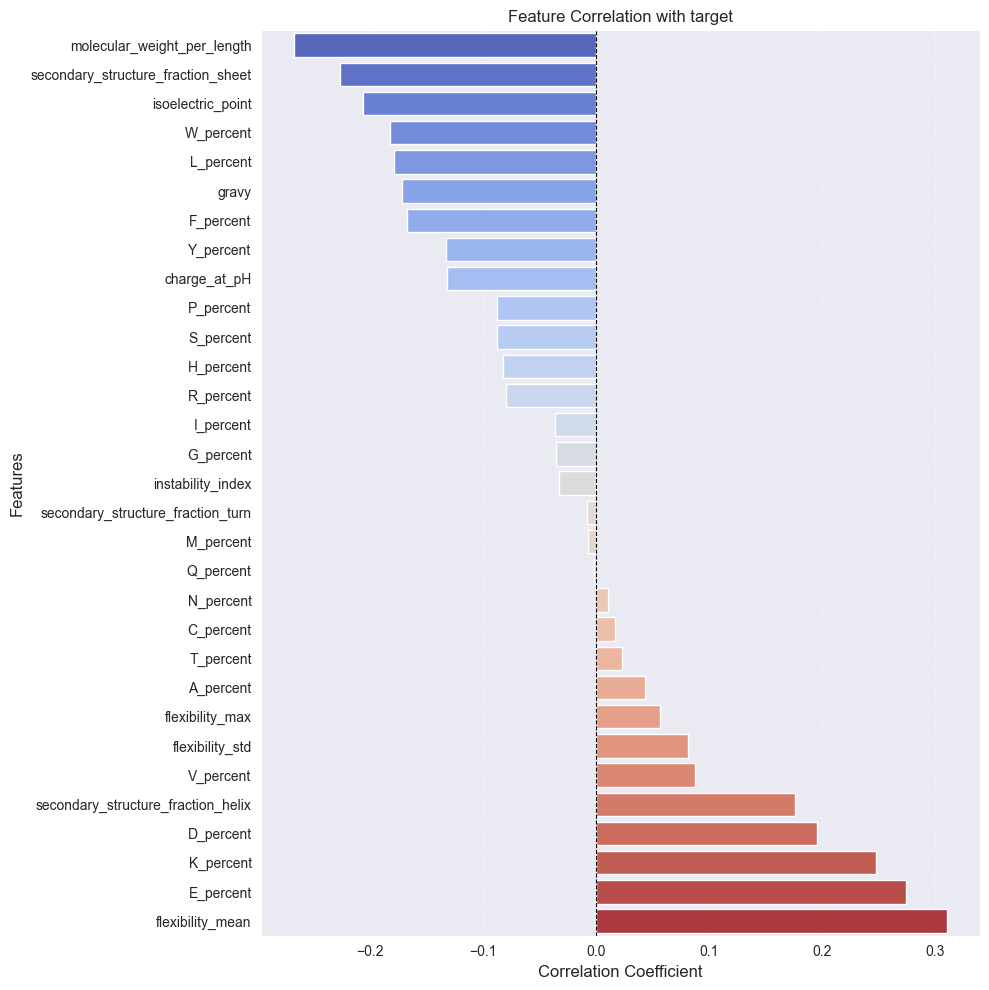

In [119]:
chem_df["label"] = df["label"]
target_col = "label"
correlations = chem_df.corr()[target_col].drop(target_col).sort_values()

plt.figure(figsize=(10, 10))
sns.barplot(
    x=correlations.values,
    y=correlations.index,
    hue=correlations.index,
    palette="coolwarm",
    legend=False,
)

plt.title(f"Feature Correlation with target")
plt.xlabel("Correlation Coefficient", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()

plt.show()

### Training models on those 3 feature sets

In [95]:
y_train = df["label"]
y_test = test_df["label"]

In [97]:
X_train = one_hot_encode(df["aa_seq"], flatten_output=True, length=310)
X_test = one_hot_encode(test_df["aa_seq"], flatten_output=True, length=310)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

one_hot_models = train_classification_models(X_train, X_test, y_train, y_test)

              Model  Accuracy  Precision (CT)  Recall (CT)  F1 Score ROC AUC  Time (sec)
                SVC    0.6613          0.6387       0.5507    0.5914       -     19.4000
         GaussianNB    0.6484          0.6058       0.6014    0.6036  0.6693      0.2300
      Random Forest    0.6387          0.6161       0.5000    0.5520  0.6773      5.9300
Logistic Regression    0.6194          0.5714       0.5797    0.5755  0.6556      0.6200


              Model  Accuracy  Precision (CT)  Recall (CT)  F1 Score ROC AUC  Time (sec)
Logistic Regression    0.7129          0.6690       0.7029    0.6855  0.7804      0.4400
                SVC    0.7032          0.6667       0.6667    0.6667       -     24.9600
      Random Forest    0.6968          0.6864       0.5870    0.6328  0.7374      6.5200
         GaussianNB    0.6194          0.5588       0.6884    0.6169  0.6390      0.3000


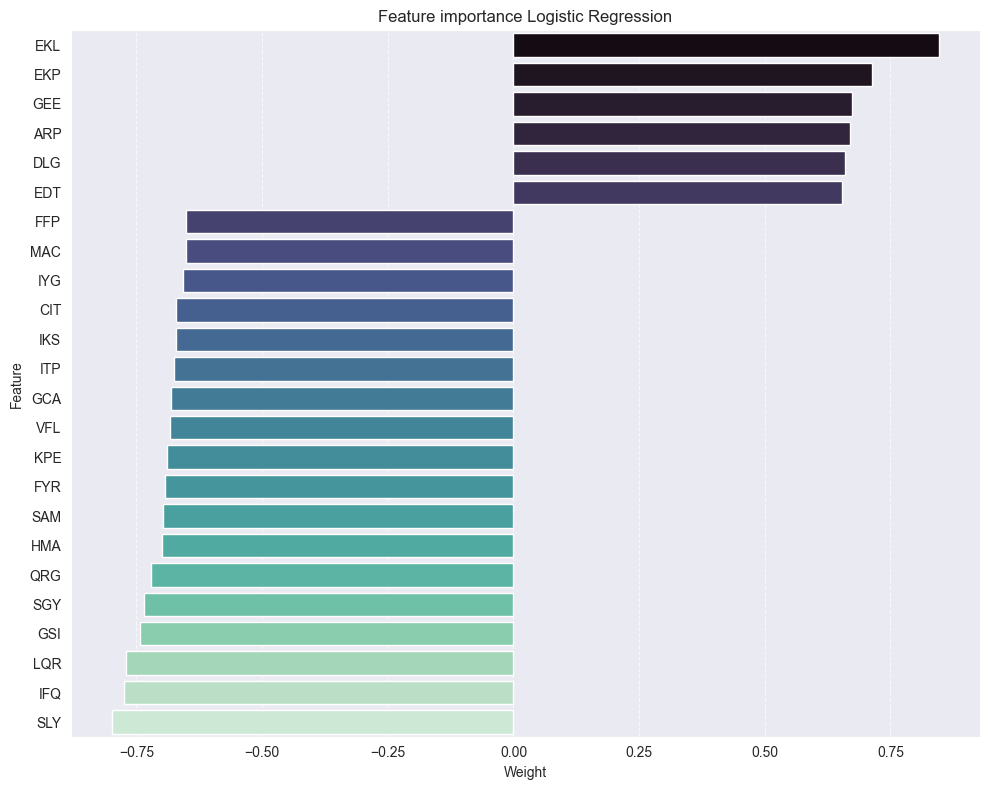

Feature  Importance
    EKL    0.845915
    EKP    0.713222
    GEE    0.674152
    ARP    0.669787
    DLG    0.659457
    EDT    0.654069
    FFP   -0.650811
    MAC   -0.651898
    IYG   -0.658141
    CIT   -0.670615
    IKS   -0.672293
    ITP   -0.676250
    GCA   -0.681315
    VFL   -0.682882
    KPE   -0.689531
    FYR   -0.693959
    SAM   -0.698073
    HMA   -0.699845
    QRG   -0.721332
    SGY   -0.734465
    GSI   -0.742707
    LQR   -0.771374
    IFQ   -0.775159
    SLY   -0.798016


In [98]:
X_train, kmers = kmer_counter(df["aa_seq"], k=3)
X_test = kmer_counter(test_df["aa_seq"], k=3)[0]

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

kmer_three_models = train_classification_models(X_train, X_test, y_train, y_test)
visualize_feature_importance(kmer_three_models["Logistic Regression"], kmers, positive_threshold=0.65, negative_threshold=-0.65)

              Model  Accuracy  Precision (CT)  Recall (CT)  F1 Score ROC AUC  Time (sec)
                SVC    0.7774          0.7717       0.7101    0.7396       -      0.5200
Logistic Regression    0.7710          0.7376       0.7536    0.7455  0.8503      0.0300
      Random Forest    0.6935          0.6641       0.6304    0.6468  0.7696      1.1800
         GaussianNB    0.6032          0.5393       0.7464    0.6261  0.6797      0.0100


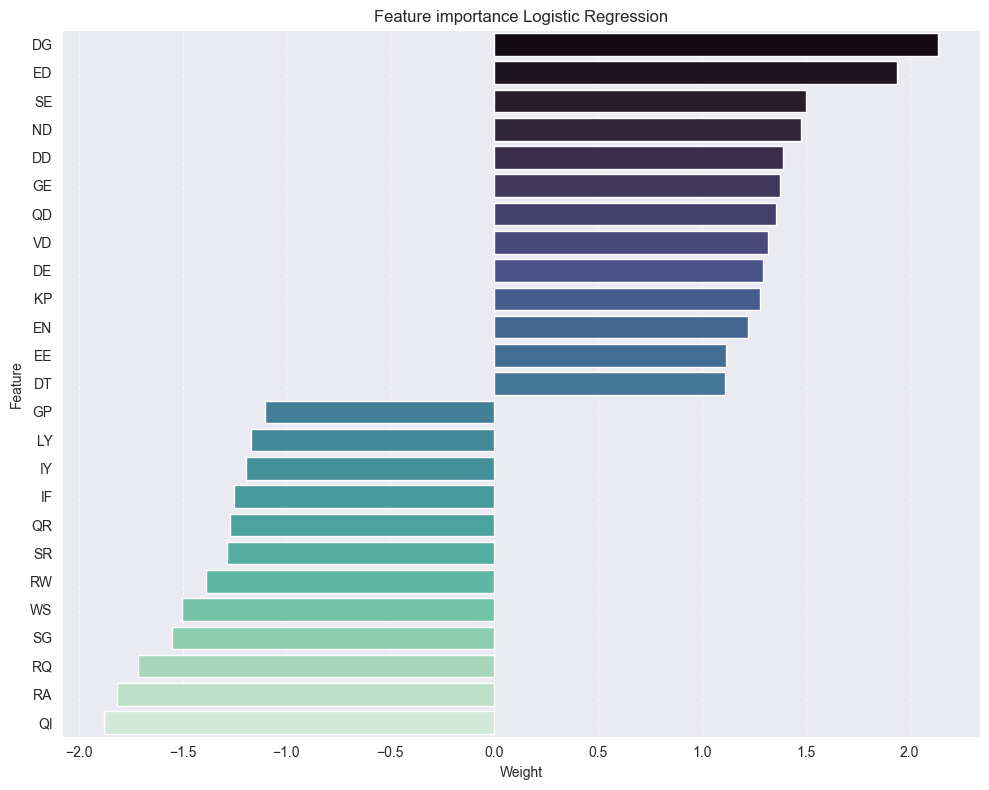

Feature  Importance
     DG    2.138125
     ED    1.937365
     SE    1.501488
     ND    1.476050
     DD    1.389874
     GE    1.377721
     QD    1.355241
     VD    1.320360
     DE    1.292202
     KP    1.281018
     EN    1.219984
     EE    1.114076
     DT    1.113794
     GP   -1.102676
     LY   -1.169984
     IY   -1.192203
     IF   -1.254227
     QR   -1.269835
     SR   -1.287370
     RW   -1.387048
     WS   -1.501363
     SG   -1.550699
     RQ   -1.716619
     RA   -1.814498
     QI   -1.878046


In [100]:
X_train, kmers = kmer_counter(df["aa_seq"], k=2)
X_test = kmer_counter(test_df["aa_seq"], k=2)[0]

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

kmer_three_models = train_classification_models(X_train, X_test, y_train, y_test)
visualize_feature_importance(kmer_three_models["Logistic Regression"], kmers, positive_threshold=1.1, negative_threshold=-1.1)

              Model  Accuracy  Precision (CT)  Recall (CT)  F1 Score ROC AUC  Time (sec)
      Random Forest    0.7903          0.7704       0.7536    0.7619  0.8535      1.6400
                SVC    0.7806          0.7536       0.7536    0.7536       -      0.2100
Logistic Regression    0.7742          0.7429       0.7536    0.7482  0.8578      0.0200
         GaussianNB    0.7484          0.7459       0.6594    0.7000  0.8072      0.0000


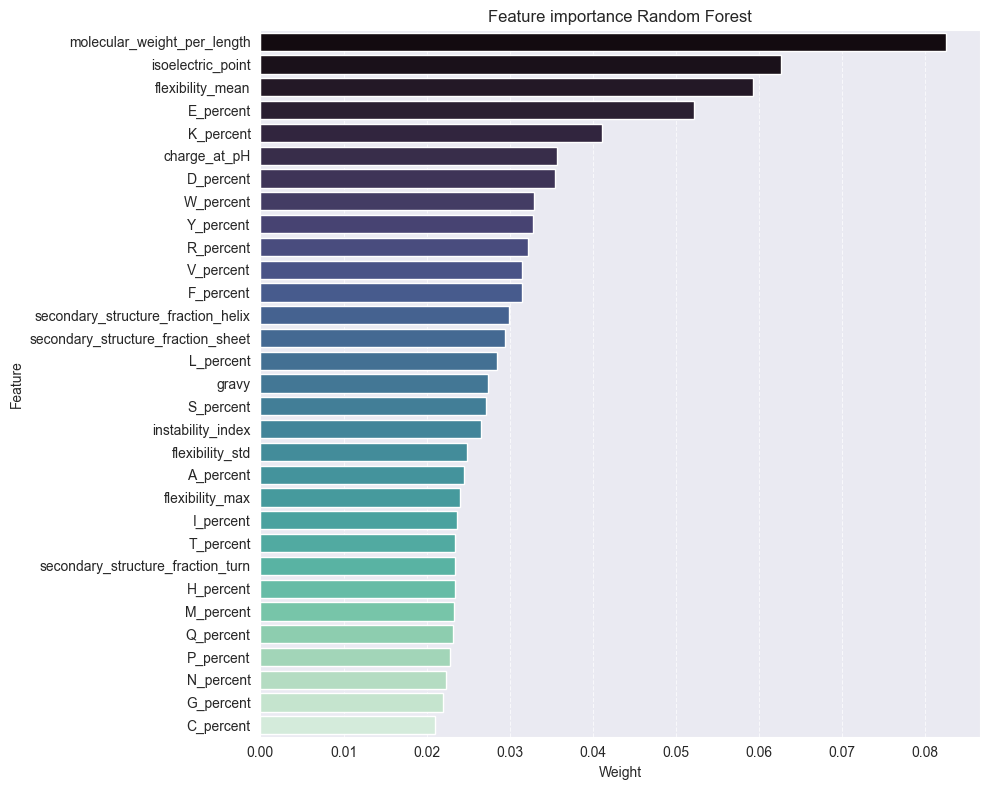

                           Feature  Importance
       molecular_weight_per_length    0.082456
                 isoelectric_point    0.062606
                  flexibility_mean    0.059217
                         E_percent    0.052129
                         K_percent    0.041072
                      charge_at_pH    0.035648
                         D_percent    0.035437
                         W_percent    0.032937
                         Y_percent    0.032766
                         R_percent    0.032200
                         V_percent    0.031436
                         F_percent    0.031416
secondary_structure_fraction_helix    0.029905
secondary_structure_fraction_sheet    0.029431
                         L_percent    0.028511
                             gravy    0.027385
                         S_percent    0.027116
                 instability_index    0.026506
                   flexibility_std    0.024906
                         A_percent    0.024472
             

In [126]:
X_train, features = extract_physicochemical_features(df["aa_seq"])
X_test = extract_physicochemical_features(test_df["aa_seq"])[0]

std_scaler = StandardScaler()
X_train = std_scaler.fit_transform(X_train)
X_test = std_scaler.transform(X_test)

physicochemical_models = train_classification_models(X_train, X_test, y_train, y_test)
visualize_feature_importance(physicochemical_models["Random Forest"], features, positive_threshold=0, negative_threshold=0, model_type="Random Forest")

In [132]:
X_train_k3, _ = kmer_counter(df["aa_seq"], k=3)
X_test_k3 = kmer_counter(test_df["aa_seq"], k=3)[0]

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_k3)
X_test_scaled = scaler.transform(X_test_k3)

lr_param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'l1_ratio': [0, 1],
    'solver': ['liblinear', 'saga']
}

lr_grid = GridSearchCV(
    estimator=LogisticRegression(random_state=STUDENT_ID),
    param_grid=lr_param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

start_time = time.time()
lr_grid.fit(X_train_scaled, y_train)
elapsed_time = time.time() - start_time

print(f"Час підбору: {elapsed_time:.2f} сек")
print(f"Найкращі параметри LR: {lr_grid.best_params_}")
print(f"Найкращий Accuracy: {lr_grid.best_score_:.4f}\n")

best_lr = lr_grid.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)
y_prob_lr = best_lr.predict_proba(X_test_scaled)[:, 1]

print("Метрики на тестовій вибірці:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_lr):.4f}")
print(f"ROC AUC:   {roc_auc_score(y_test, y_prob_lr):.4f}")

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Час підбору: 51.23 сек
Найкращі параметри LR: {'C': 0.01, 'l1_ratio': 0, 'solver': 'liblinear'}
Найкращий Accuracy: 0.7175

Метрики на тестовій вибірці:
Accuracy:  0.7355
Precision: 0.7029
Recall:    0.7029
F1 Score:  0.7029
ROC AUC:   0.8053


In [133]:
X_train_phys, _ = extract_physicochemical_features(df["aa_seq"])
X_test_phys = extract_physicochemical_features(test_df["aa_seq"])[0]

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_k3)
X_test_scaled = scaler.transform(X_test_k3)

rf_param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=STUDENT_ID, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

start_time = time.time()
rf_grid.fit(X_train_phys, y_train)
elapsed_time = time.time() - start_time

print(f"Час підбору: {elapsed_time:.2f} сек")
print(f"Найкращі параметри RF: {rf_grid.best_params_}")
print(f"Найкращий Accuracy: {rf_grid.best_score_:.4f}\n")

best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test_phys)
y_prob_rf = best_rf.predict_proba(X_test_phys)[:, 1]

print("Метрики на тестовій вибірці:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC AUC:   {roc_auc_score(y_test, y_prob_rf):.4f}")

Fitting 3 folds for each of 216 candidates, totalling 648 fits
Час підбору: 141.12 сек
Найкращі параметри RF: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 300}
Найкращий Accuracy: 0.7719

Метрики на тестовій вибірці:
Accuracy:  0.7871
Precision: 0.7647
Recall:    0.7536
F1 Score:  0.7591
ROC AUC:   0.8568


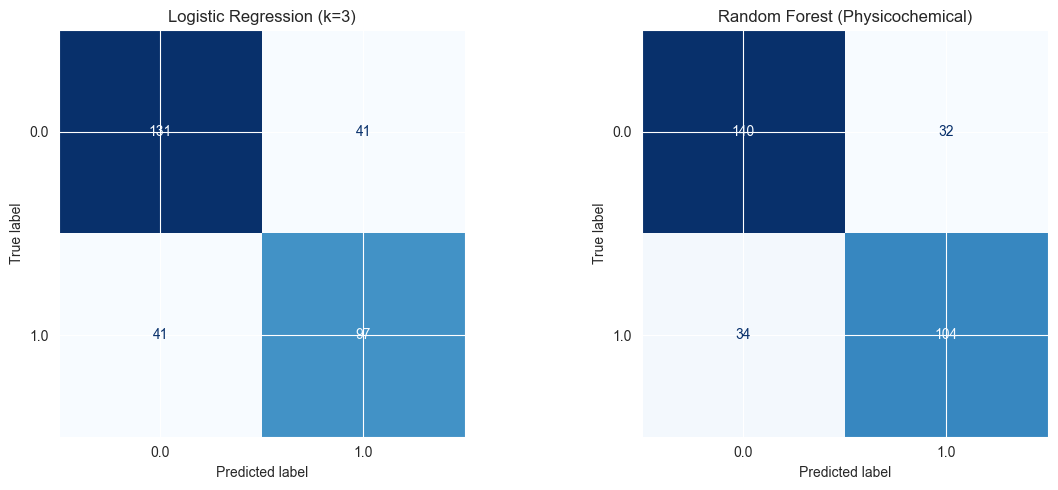

In [139]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_lr, 
    ax=axes[0], 
    cmap='Blues', 
    colorbar=False
)
axes[0].set_title('Logistic Regression (k=3)')

ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_rf, 
    ax=axes[1], 
    cmap='Blues', 
    colorbar=False
)
axes[1].set_title('Random Forest (Physicochemical)')

plt.tight_layout()
plt.show()